In [2]:
## Importing Libraries and Loading Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/customer_churn_clean.csv"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


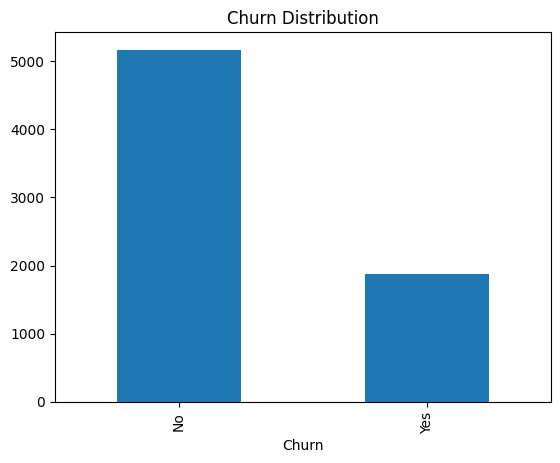

In [3]:
## Visualizing Churn Distribution
df["Churn"].value_counts().plot(
    kind="bar",
    title="Churn Distribution"
)

plt.show()

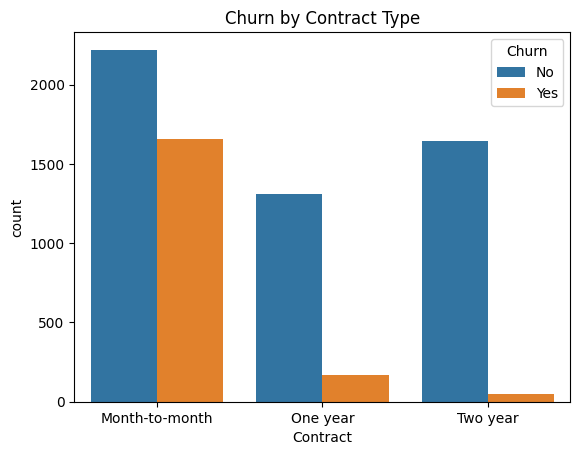

In [4]:
# Visualizing Churn by Contract Type
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract Type")
plt.show()

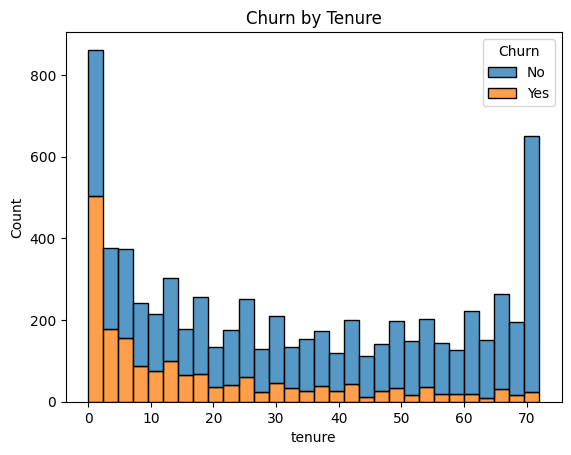

In [5]:
# Visualizing Churn by Tenure
sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Churn by Tenure")
plt.show()

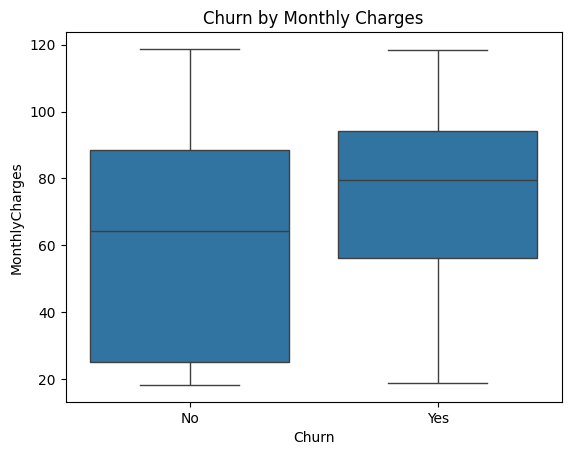

In [6]:
# Visualizing Monthly Charges by Churn
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Churn by Monthly Charges")
plt.show()

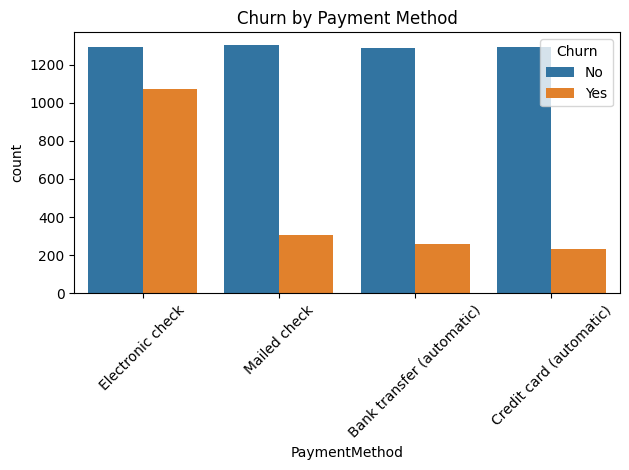

In [7]:
# Visualizing Churn by Payment Method
sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.xticks(rotation=45)
plt.title("Churn by Payment Method")
plt.tight_layout()
plt.show()

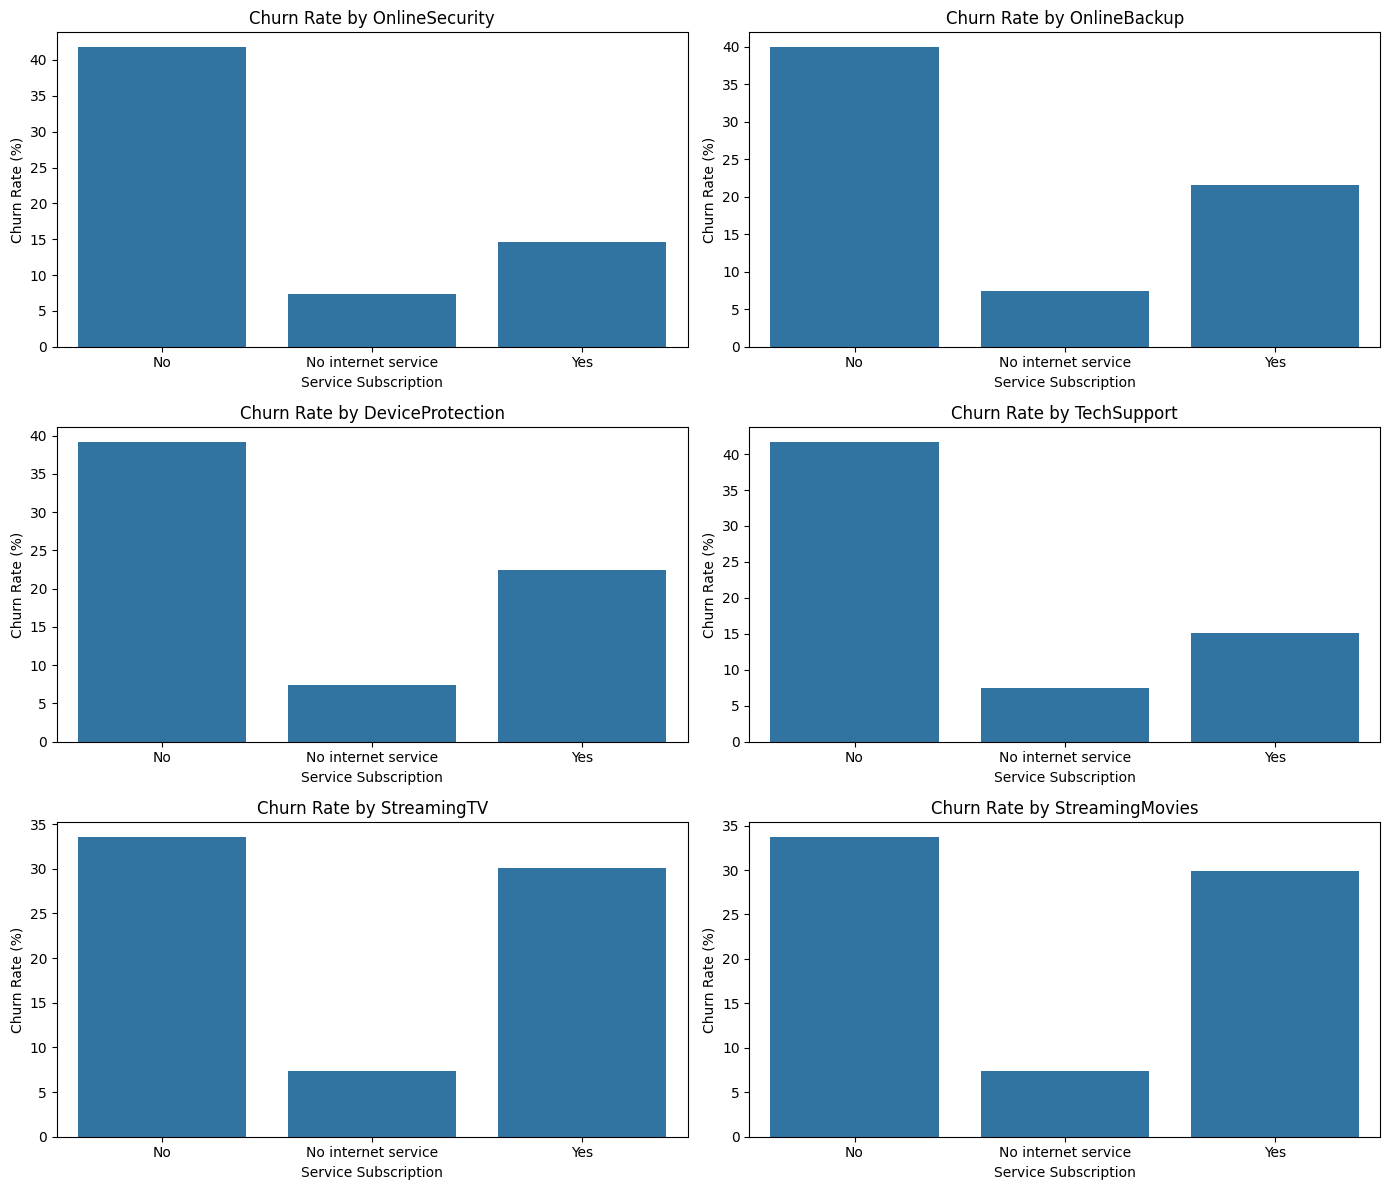

In [ ]:
# Churn by Additional Services
additional_services = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

fig, axs = plt.subplots(3, 2, figsize=(14, 12))
axs = axs.ravel()

for i, ax in enumerate(axs):
    churn_rate = (
        df.groupby(additional_services[i], observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
    )

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {additional_services[i]}")
    ax.set_xlabel("Service Subscription")
    ax.set_ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()


In [ ]:
# Calculating principal metrics for dashboard
total_clients = len(df)

canceled_clients = (
    df["Churn"] == "Yes"
).sum()

churn_rate = (
    canceled_clients / total_clients
) * 100

monthly_charges_sum = (
    df[df["Churn"] == "No"]["MonthlyCharges"].sum()
)

lost_monthly_charges_sum = (
    df[df["Churn"] == "Yes"]["MonthlyCharges"].sum()
)

tenure_mean = df["tenure"].mean()

print(f"Total of clients: {total_clients}")
print(f"Total of canceled clients: {canceled_clients}")
print(f"Retention Rate: {100 - churn_rate:.2f}%")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Total Monthly Charges: ${monthly_charges_sum:.2f}")
print(f"Lost Monthly Charges: ${lost_monthly_charges_sum:.2f}")
print(f"Average Tenure: {tenure_mean:.2f} months")


Total of clients: 7043
Total of canceled clients: 1869
Retention Rate: 73.46%
Churn Rate: 26.54%
Total Monthly Charges: $316985.75
Lost Monthly Charges: $139130.85
Average Tenure: 32.37 months
